In [1]:
# Cell 1: Slice the Colab-built series (chunks 1-3, unclipped, whole period) to the complete window
# 2021-07-01 .. 2021-10-01 (file clock, end exclusive) and run first sanity checks.
from pathlib import Path
from datetime import datetime
import polars as pl

PROC = Path("../data/processed")
SRC = PROC / "series_after_chunk_3.parquet"
OUT = PROC / "series_julsep.parquet"
WIN_START, WIN_END = datetime(2021, 7, 1), datetime(2021, 10, 1)

full = pl.read_parquet(SRC)
print(f"source: {SRC.name} | {SRC.stat().st_size / 2**20:.2f} MiB | shape {full.shape}")

s = full.filter((pl.col("minute_local") >= WIN_START) & (pl.col("minute_local") < WIN_END)).sort("minute_local")
expected = int((WIN_END - WIN_START).total_seconds() // 60)
print(f"window rows: {s.height:,} (expected {expected:,}) | first {s['minute_local'][0]} | last {s['minute_local'][-1]}")
print("minute steps all 60 s:", (s["minute_epoch"].diff().drop_nulls() == 60).all())

print(f"minutes with null power: {s['power_W'].null_count():,} | with power = 0: {(s['power_W'] == 0).sum():,}")
print(f"power_W min/max: {s['power_W'].min():.1f} / {s['power_W'].max():.1f}")
print(f"n_gpu_equiv max: {s['n_gpu_equiv'].max():.2f} (must be <= 448)")

daily_null = (s.group_by(pl.col("minute_local").dt.date().alias("day"))
                .agg(pl.col("power_W").null_count().alias("null_min"))
                .filter(pl.col("null_min") > 0).sort("day"))
print("\ndays with null-power minutes:")
print(daily_null)

s.write_parquet(OUT)
print(f"\nwritten: {OUT} | {OUT.stat().st_size / 2**20:.2f} MiB")

source: series_after_chunk_3.parquet | 9.31 MiB | shape (394560, 12)
window rows: 132,480 (expected 132,480) | first 2021-07-01 00:00:00 | last 2021-09-30 23:59:00
minute steps all 60 s: True
minutes with null power: 2,480 | with power = 0: 0
power_W min/max: 4.8 / 64531.7
n_gpu_equiv max: 429.00 (must be <= 448)

days with null-power minutes:
shape: (4, 2)
┌────────────┬──────────┐
│ day        ┆ null_min │
│ ---        ┆ ---      │
│ date       ┆ u32      │
╞════════════╪══════════╡
│ 2021-07-15 ┆ 982      │
│ 2021-08-10 ┆ 684      │
│ 2021-08-11 ┆ 92       │
│ 2021-09-16 ┆ 722      │
└────────────┴──────────┘

written: ../data/processed/series_julsep.parquet | 7.30 MiB


In [3]:
# Cell 2: Load the Jul-Sep feature series; show schema, null counts and a monthly summary of power.
import polars as pl
from pathlib import Path

FEAT = Path("../data/processed/series_julsep_features.parquet")
df = pl.read_parquet(FEAT)
print(f"{FEAT.name} | {FEAT.stat().st_size / 2**20:.2f} MiB | shape {df.shape}\n")

print("schema and null counts:")
nulls = df.null_count().row(0)
for (name, dtype), n in zip(df.schema.items(), nulls):
    print(f"  {name:<24} {str(dtype):<20} nulls {n:>7,}")

monthly = (df.group_by(pl.col("minute_local").dt.strftime("%Y-%m").alias("month"))
             .agg(pl.len().alias("minutes"),
                  pl.col("power_W").null_count().alias("null_power"),
                  (pl.col("power_W").mean() / 1000).round(2).alias("mean_kW"),
                  (pl.col("power_W").median() / 1000).round(2).alias("median_kW"),
                  (pl.col("power_W").quantile(0.99) / 1000).round(2).alias("p99_kW"),
                  (pl.col("power_W").max() / 1000).round(2).alias("max_kW"))
             .sort("month"))
print("\nmonthly power summary:")
print(monthly)

series_julsep_features.parquet | 7.69 MiB | shape (132480, 20)

schema and null counts:
  minute_epoch             Int64                nulls       0
  power_W                  Float64              nulls   2,316
  util_gpu_mean            Float64              nulls   2,480
  util_mem_mean            Float64              nulls   2,480
  temp_gpu_mean            Float64              nulls   2,480
  temp_mem_mean            Float64              nulls   2,480
  mem_used_sum             Float64              nulls   2,316
  mem_free_sum             Float64              nulls   2,316
  n_gpu_equiv              Float64              nulls       0
  n_gpu_streams            Int64                nulls       0
  n_edge_streams           Int64                nulls       0
  minute_local             Datetime(time_unit='us', time_zone=None) nulls       0
  cluster_gap              Boolean              nulls       0
  active_jobs              Int64                nulls       0
  active_gpu_jobs       

split boundaries (by minute index): train < 2021-09-03 09:36:00 <= val < 2021-09-17 04:48:00 <= test

per-split level (normal days only):
shape: (3, 6)
┌───────┬───────────────┬─────────┬────────┬────────┬────────┐
│ split ┆ valid_minutes ┆ mean_kW ┆ std_kW ┆ min_kW ┆ max_kW │
│ ---   ┆ ---           ┆ ---     ┆ ---    ┆ ---    ┆ ---    │
│ str   ┆ u32           ┆ f64     ┆ f64    ┆ f64    ┆ f64    │
╞═══════╪═══════════════╪═════════╪════════╪════════╪════════╡
│ train ┆ 89856         ┆ 30.98   ┆ 7.97   ┆ 0.0    ┆ 49.57  │
│ val   ┆ 18432         ┆ 30.4    ┆ 5.13   ┆ 17.73  ┆ 42.2   │
│ test  ┆ 19872         ┆ 25.56   ┆ 5.78   ┆ 10.96  ┆ 41.22  │
└───────┴───────────────┴─────────┴────────┴────────┴────────┘


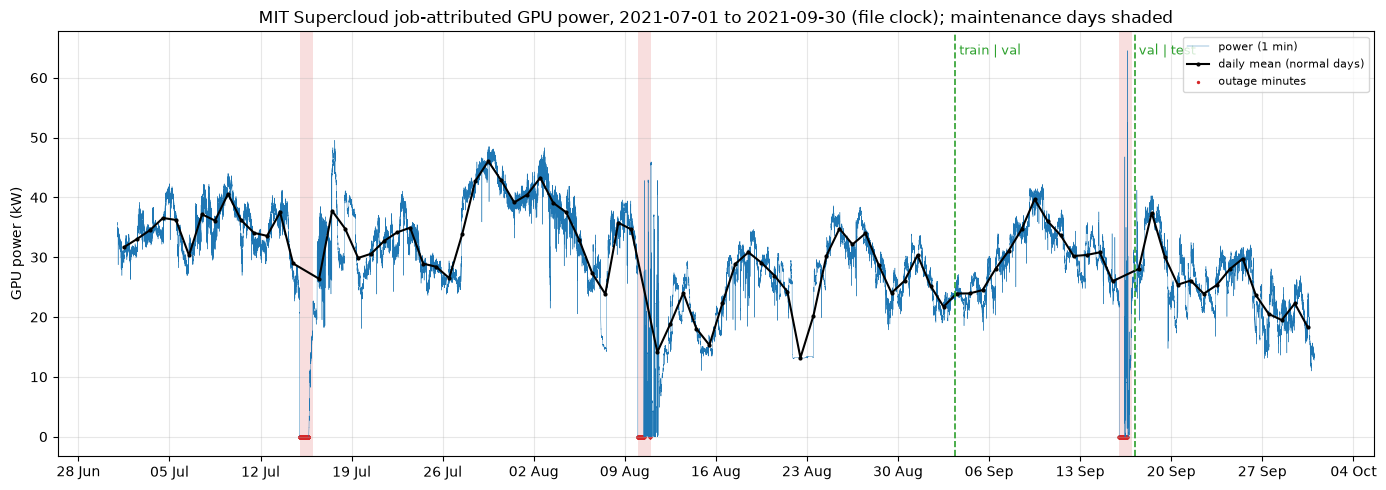

saved: ../reports/figures/eda_julsep/01_series_jul_sep.png

daily mean kW (normal days): min 13.2 | max 46.0 | first 7 days 34.2 | last 7 days 23.1

zero-power minutes on non-maintenance days:
shape: (1, 2)
┌────────────┬──────────┐
│ day        ┆ zero_min │
│ ---        ┆ ---      │
│ date       ┆ u32      │
╞════════════╪══════════╡
│ 2021-08-11 ┆ 92       │
└────────────┴──────────┘


In [5]:
# Cell 3 (v2): Whole Jul-Sep series with daily mean, maintenance days shaded, outages marked,
# and the chronological 70/15/15 split boundaries; per-split level summary.
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from datetime import datetime, timedelta, time as dtime

FIG = Path("../reports/figures/eda_julsep")
FIG.mkdir(parents=True, exist_ok=True)

n = df.height
i_tr, i_va = int(n * 0.70), int(n * 0.85)
b_tr, b_va = df["minute_local"][i_tr], df["minute_local"][i_va]
print(f"split boundaries (by minute index): train < {b_tr} <= val < {b_va} <= test")

split = (df.with_columns(pl.when(pl.int_range(pl.len()) < i_tr).then(pl.lit("train"))
                           .when(pl.int_range(pl.len()) < i_va).then(pl.lit("val"))
                           .otherwise(pl.lit("test")).alias("split"))
           .filter(~pl.col("outage") & ~pl.col("maint_day"))
           .group_by("split", maintain_order=True)
           .agg(pl.len().alias("valid_minutes"),
                (pl.col("power_W").mean() / 1000).round(2).alias("mean_kW"),
                (pl.col("power_W").std() / 1000).round(2).alias("std_kW"),
                (pl.col("power_W").min() / 1000).round(2).alias("min_kW"),
                (pl.col("power_W").max() / 1000).round(2).alias("max_kW")))
print("\nper-split level (normal days only):")
print(split)

daily = (df.filter(~pl.col("outage") & ~pl.col("maint_day"))
           .group_by(pl.col("minute_local").dt.date().alias("day"))
           .agg((pl.col("power_W").mean() / 1000).alias("mean_kW")).sort("day"))
daily_x = [datetime.combine(d, dtime(12, 0)) for d in daily["day"].to_list()]
maint_days = df.filter(pl.col("maint_day"))["minute_local"].dt.date().unique().sort().to_list()
out = df.filter(pl.col("outage"))

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df["minute_local"].to_list(), (df["power_W"] / 1000).to_list(), lw=0.3, color="tab:blue", label="power (1 min)")
ax.plot(daily_x, daily["mean_kW"].to_list(), color="black", lw=1.5, marker="o", ms=2, label="daily mean (normal days)")
for d in maint_days:
    start = datetime.combine(d, dtime(0, 0))
    ax.axvspan(start, start + timedelta(days=1), color="tab:red", alpha=0.15, lw=0)
ax.scatter(out["minute_local"].to_list(), [0] * out.height, s=2, color="tab:red", label="outage minutes")
ymax = ax.get_ylim()[1]
for b, lab in [(b_tr, "train | val"), (b_va, "val | test")]:
    ax.axvline(b, color="tab:green", ls="--", lw=1.2)
    ax.text(b, ymax * 0.97, f" {lab}", color="tab:green", va="top", fontsize=9)
ax.set_ylabel("GPU power (kW)")
ax.set_title("MIT Supercloud job-attributed GPU power, 2021-07-01 to 2021-09-30 (file clock); maintenance days shaded")
ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax.legend(loc="upper right", fontsize=8)
ax.grid(alpha=0.3)
fig.tight_layout()
p = FIG / "01_series_jul_sep.png"
fig.savefig(p, dpi=150)
plt.show()
print("saved:", p)

print("\ndaily mean kW (normal days): min {:.1f} | max {:.1f} | first 7 days {:.1f} | last 7 days {:.1f}".format(
    daily["mean_kW"].min(), daily["mean_kW"].max(), daily["mean_kW"].head(7).mean(), daily["mean_kW"].tail(7).mean()))
zero_days = (df.filter((pl.col("power_W") == 0) & ~pl.col("maint_day"))
               .group_by(pl.col("minute_local").dt.date().alias("day")).agg(pl.len().alias("zero_min")).sort("day"))
print("\nzero-power minutes on non-maintenance days:")
print(zero_days)

valid minutes: 128,068 of 132,480 | post-maintenance zero minutes excluded: 92

DAILY: hour-of-day share of within-day variance = 0.072 | permutation null mean 0.011, 95th pct 0.017 | p = 0.000
WEEKLY: weekday share of detrended daily-mean variance = 0.049 | permutation null mean 0.073, 95th pct 0.146 | p = 0.693 | days used 83

weekday effect (detrended daily mean, kW):
shape: (7, 4)
┌─────┬───────────┬──────────┬─────┐
│ wd  ┆ detr_kW   ┆ sd       ┆ n   │
│ --- ┆ ---       ┆ ---      ┆ --- │
│ i8  ┆ f64       ┆ f64      ┆ u32 │
╞═════╪═══════════╪══════════╪═════╡
│ 1   ┆ -0.925268 ┆ 4.187172 ┆ 13  │
│ 2   ┆ 0.532742  ┆ 3.400538 ┆ 11  │
│ 3   ┆ 0.294398  ┆ 4.83412  ┆ 12  │
│ 4   ┆ 1.401013  ┆ 3.918229 ┆ 10  │
│ 5   ┆ 0.812656  ┆ 3.770888 ┆ 12  │
│ 6   ┆ 0.182306  ┆ 4.09128  ┆ 12  │
│ 7   ┆ -1.480244 ┆ 5.229126 ┆ 13  │
└─────┴───────────┴──────────┴─────┘


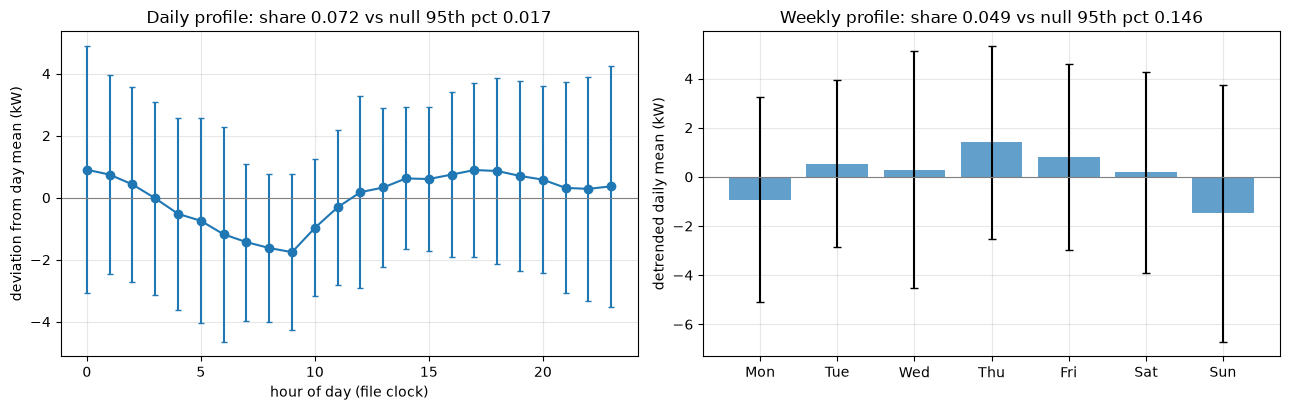

saved: ../reports/figures/eda_julsep/02_daily_weekly_profile.png


In [6]:
# Cell 4: Daily and weekly profiles. Valid minutes exclude outages, maintenance days and zero-power
# minutes on the day after a maintenance day (post-maintenance tail; EDA-only rule, provisional).
# Effect sizes are compared with a permutation null.
import numpy as np

maint_set = set(maint_days)
df = df.with_columns(
    (pl.col("minute_local").dt.date().map_elements(lambda d: (d - timedelta(days=1)) in maint_set, return_dtype=pl.Boolean)
     & (pl.col("power_W") == 0)).alias("post_maint_zero"))
df = df.with_columns((~pl.col("outage") & ~pl.col("maint_day") & ~pl.col("post_maint_zero")).alias("valid"))
print(f"valid minutes: {df['valid'].sum():,} of {df.height:,} | post-maintenance zero minutes excluded: {df['post_maint_zero'].sum()}")

v = df.filter(pl.col("valid")).with_columns(
    pl.col("minute_local").dt.date().alias("day"),
    pl.col("minute_local").dt.hour().alias("hour"),
    pl.col("minute_local").dt.weekday().alias("wd"))  # 1 = Mon ... 7 = Sun

rng = np.random.default_rng(0)
N_PERM = 1000

# --- daily: hourly means per day, deviations from each day's mean, share explained by hour of day ---
hd = (v.group_by("day", "hour").agg((pl.col("power_W").mean() / 1000).alias("kW"))
        .with_columns((pl.col("kW") - pl.col("kW").mean().over("day")).alias("dev")).sort("day", "hour"))
dev, hours, days_h = hd["dev"].to_numpy(), hd["hour"].to_numpy(), hd["day"].to_numpy()
def share_by(group, y):
    g_mean = {g: y[group == g].mean() for g in np.unique(group)}
    fitted = np.array([g_mean[g] for g in group])
    return 1 - ((y - fitted) ** 2).sum() / ((y - y.mean()) ** 2).sum()
r2_hour = share_by(hours, dev)
null_hour = []
for _ in range(N_PERM):
    perm = hours.copy()
    for d in np.unique(days_h):
        m = days_h == d
        perm[m] = rng.permutation(perm[m])
    null_hour.append(share_by(perm, dev))
null_hour = np.array(null_hour)
print(f"\nDAILY: hour-of-day share of within-day variance = {r2_hour:.3f} | permutation null mean {null_hour.mean():.3f}, "
      f"95th pct {np.quantile(null_hour, 0.95):.3f} | p = {(null_hour >= r2_hour).mean():.3f}")
hour_prof = hd.group_by("hour").agg(pl.col("dev").mean().alias("dev_kW"), pl.col("dev").std().alias("sd")).sort("hour")

# --- weekly: daily means detrended by a centred 7-day rolling mean, share explained by weekday ---
dm = (v.group_by("day", "wd").agg((pl.col("power_W").mean() / 1000).alias("kW")).sort("day")
        .with_columns(pl.col("kW").rolling_mean(7, center=True).alias("trend"))
        .with_columns((pl.col("kW") - pl.col("trend")).alias("detr")).drop_nulls("detr"))
detr, wd = dm["detr"].to_numpy(), dm["wd"].to_numpy()
r2_wd = share_by(wd, detr)
null_wd = np.array([share_by(rng.permutation(wd), detr) for _ in range(N_PERM)])
print(f"WEEKLY: weekday share of detrended daily-mean variance = {r2_wd:.3f} | permutation null mean {null_wd.mean():.3f}, "
      f"95th pct {np.quantile(null_wd, 0.95):.3f} | p = {(null_wd >= r2_wd).mean():.3f} | days used {len(detr)}")
wd_prof = dm.group_by("wd").agg(pl.col("detr").mean().alias("detr_kW"), pl.col("detr").std().alias("sd"), pl.len().alias("n")).sort("wd")
print("\nweekday effect (detrended daily mean, kW):")
print(wd_prof)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].errorbar(hour_prof["hour"], hour_prof["dev_kW"], yerr=hour_prof["sd"], fmt="o-", capsize=2)
axes[0].axhline(0, color="grey", lw=0.8)
axes[0].set(xlabel="hour of day (file clock)", ylabel="deviation from day mean (kW)",
            title=f"Daily profile: share {r2_hour:.3f} vs null 95th pct {np.quantile(null_hour, 0.95):.3f}")
names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
axes[1].bar([names[i - 1] for i in wd_prof["wd"]], wd_prof["detr_kW"], yerr=wd_prof["sd"], capsize=3, color="tab:blue", alpha=0.7)
axes[1].axhline(0, color="grey", lw=0.8)
axes[1].set(ylabel="detrended daily mean (kW)",
            title=f"Weekly profile: share {r2_wd:.3f} vs null 95th pct {np.quantile(null_wd, 0.95):.3f}")
for a in axes: a.grid(alpha=0.3)
fig.tight_layout()
p = FIG / "02_daily_weekly_profile.png"
fig.savefig(p, dpi=150)
plt.show()
print("saved:", p)

ACF(P):  lag 1: 0.997 | lag 5: 0.992 | lag 15: 0.985 | lag 60: 0.959 | lag 360: 0.858 | lag 720: 0.760 | lag 1440: 0.642 | lag 2880: 0.401
first lag with ACF(P) < 0.5: 2096 min
daily bump check: ACF at 1440 = 0.642 vs min over 600-1440 = 0.642
ACF(dP): lag 1: -0.170 | lag 2: -0.096 | lag 3: -0.032 | lag 4: -0.086 | lag 5: +0.109 | lag 10: +0.115 | lag 15: +0.113 | 95% band ±0.005

longest valid segment: 51,082 min (2021-08-11 12:38:00 .. 2021-09-15 23:59:00)
PACF(P) lags 1-6: +0.998 | +0.138 | +0.103 | +0.040 | +0.053 | +0.002 | 95% band ±0.009

persistence baseline (P(t+h) = P(t)), valid pairs only:
shape: (9, 6)
┌───────┬───────┬───────┬────────┬─────────┬──────────────┐
│ h_min ┆ split ┆ pairs ┆ MAE_kW ┆ RMSE_kW ┆ p95_absdP_kW │
│ ---   ┆ ---   ┆ ---   ┆ ---    ┆ ---     ┆ ---          │
│ i64   ┆ str   ┆ i64   ┆ f64    ┆ f64     ┆ f64          │
╞═══════╪═══════╪═══════╪════════╪═════════╪══════════════╡
│ 1     ┆ train ┆ 89751 ┆ 0.343  ┆ 0.665   ┆ 1.075        │
│ 1     ┆ val   ┆ 

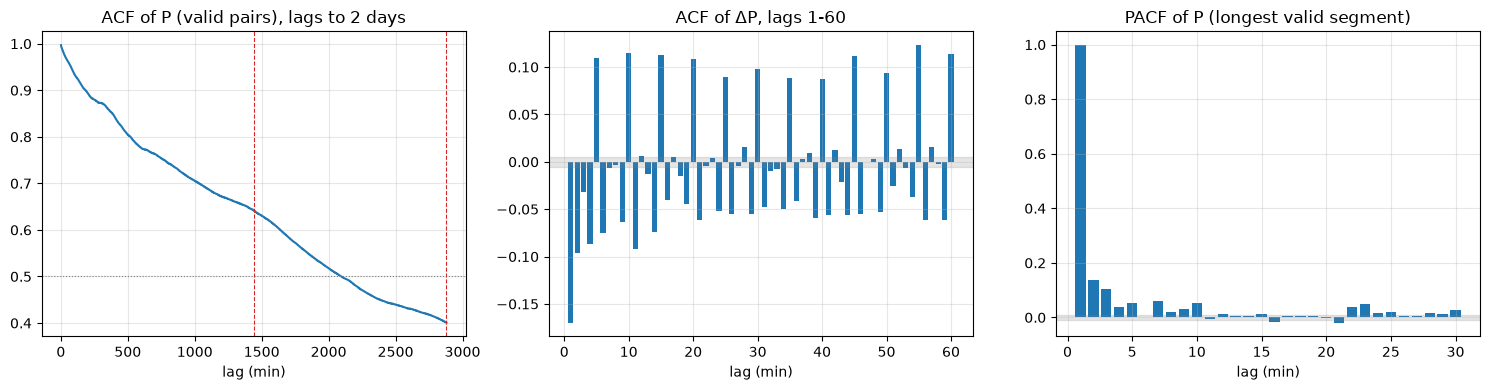

saved: ../reports/figures/eda_julsep/03_acf_pacf.png


In [7]:
# Cell 5: ACF of P and dP on valid pairs (outages and maintenance masked), PACF on the longest valid
# segment, and the persistence baseline per split and horizon (both endpoints valid).
x = (df["power_W"] / 1000).to_numpy()
valid = df["valid"].to_numpy()
mu = np.nanmean(x[valid])

def acf_valid(y, ok, lags):
    out = []
    for k in lags:
        m = ok[:-k] & ok[k:]
        a, b = y[:-k][m] - mu_y, y[k:][m] - mu_y
        out.append((a * b).sum() / np.sqrt((a * a).sum() * (b * b).sum()))
    return np.array(out)

mu_y = mu
lags = np.arange(1, 2881)
acf_p = acf_valid(x, valid, lags)

dp = np.full_like(x, np.nan); dp[1:] = x[1:] - x[:-1]
ok_dp = valid.copy(); ok_dp[1:] &= valid[:-1]; ok_dp[0] = False
mu_y = np.nanmean(dp[ok_dp])
acf_dp = acf_valid(dp, ok_dp, np.arange(1, 61))
mu_y = mu

show = [1, 5, 15, 60, 360, 720, 1440, 2880]
print("ACF(P):  " + " | ".join(f"lag {k}: {acf_p[k - 1]:.3f}" for k in show))
print(f"first lag with ACF(P) < 0.5: {int(lags[np.argmax(acf_p < 0.5)])} min")
print(f"daily bump check: ACF at 1440 = {acf_p[1439]:.3f} vs min over 600-1440 = {acf_p[599:1440].min():.3f}")
band = 1.96 / np.sqrt(ok_dp.sum())
print("ACF(dP): " + " | ".join(f"lag {k}: {acf_dp[k - 1]:+.3f}" for k in [1, 2, 3, 4, 5, 10, 15]) + f" | 95% band ±{band:.3f}")

# longest contiguous valid segment for the PACF
edges = np.diff(np.concatenate([[0], valid.astype(int), [0]]))
starts, ends = np.where(edges == 1)[0], np.where(edges == -1)[0]
j = np.argmax(ends - starts)
seg = x[starts[j]:ends[j]]
print(f"\nlongest valid segment: {len(seg):,} min ({df['minute_local'][int(starts[j])]} .. {df['minute_local'][int(ends[j]) - 1]})")
try:
    from statsmodels.tsa.stattools import pacf
    pacf_p = pacf(seg, nlags=30, method="ywm")
    print("PACF(P) lags 1-6: " + " | ".join(f"{v:+.3f}" for v in pacf_p[1:7]) + f" | 95% band ±{1.96 / np.sqrt(len(seg)):.3f}")
except ImportError:
    pacf_p = None
    print("statsmodels not available: PACF skipped")

# persistence baseline: forecast P(t+h) = P(t)
split_lab = np.where(np.arange(n) < i_tr, "train", np.where(np.arange(n) < i_va, "val", "test"))
rows = []
for h in (1, 5, 15):
    m = valid[:-h] & valid[h:]
    err = x[h:] - x[:-h]
    for s in ("train", "val", "test"):
        mm = m & (split_lab[h:] == s)
        e = err[mm]
        rows.append({"h_min": h, "split": s, "pairs": int(mm.sum()),
                     "MAE_kW": round(float(np.abs(e).mean()), 3), "RMSE_kW": round(float(np.sqrt((e ** 2).mean())), 3),
                     "p95_absdP_kW": round(float(np.quantile(np.abs(e), 0.95)), 3)})
persist = pl.DataFrame(rows)
print("\npersistence baseline (P(t+h) = P(t)), valid pairs only:")
print(persist)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(lags, acf_p); axes[0].axhline(0.5, color="grey", ls=":", lw=0.8)
for k in (1440, 2880): axes[0].axvline(k, color="tab:red", ls="--", lw=0.8)
axes[0].set(title="ACF of P (valid pairs), lags to 2 days", xlabel="lag (min)")
axes[1].bar(np.arange(1, 61), acf_dp, width=0.8); axes[1].axhspan(-band, band, color="grey", alpha=0.2)
axes[1].set(title="ACF of ΔP, lags 1-60", xlabel="lag (min)")
if pacf_p is not None:
    axes[2].bar(np.arange(1, 31), pacf_p[1:], width=0.8)
    b2 = 1.96 / np.sqrt(len(seg)); axes[2].axhspan(-b2, b2, color="grey", alpha=0.2)
axes[2].set(title="PACF of P (longest valid segment)", xlabel="lag (min)")
for a in axes: a.grid(alpha=0.3)
fig.tight_layout()
p = FIG / "03_acf_pacf.png"
fig.savefig(p, dpi=150)
plt.show()
print("saved:", p)

ACF(dP) lags 1-30:
   1: -0.170 |  2: -0.096 |  3: -0.032 |  4: -0.086 |  5: +0.109 |  6: -0.075 |  7: -0.006 |  8: -0.003 |  9: -0.064 | 10: +0.115
  11: -0.092 | 12: +0.006 | 13: -0.013 | 14: -0.074 | 15: +0.113 | 16: -0.040 | 17: +0.005 | 18: -0.015 | 19: -0.045 | 20: +0.109
  21: -0.062 | 22: -0.004 | 23: +0.004 | 24: -0.052 | 25: +0.089 | 26: -0.056 | 27: -0.004 | 28: +0.016 | 29: -0.055 | 30: +0.098

by minute of hour mod 5:
shape: (5, 6)
┌─────────┬───────┬─────────┬─────────────┬───────────┬──────────────┐
│ mm_mod5 ┆ n     ┆ mean_dP ┆ mean_abs_dP ┆ mean_edge ┆ mean_streams │
│ ---     ┆ ---   ┆ ---     ┆ ---         ┆ ---       ┆ ---          │
│ i8      ┆ u32   ┆ f64     ┆ f64         ┆ f64       ┆ f64          │
╞═════════╪═══════╪═════════╪═════════════╪═══════════╪══════════════╡
│ 0       ┆ 25608 ┆ -0.2077 ┆ 0.3763      ┆ 1.08      ┆ 333.68       │
│ 1       ┆ 25612 ┆ 0.2052  ┆ 0.3687      ┆ 1.13      ┆ 333.71       │
│ 2       ┆ 25612 ┆ -0.0007 ┆ 0.2772      ┆ 1.17      

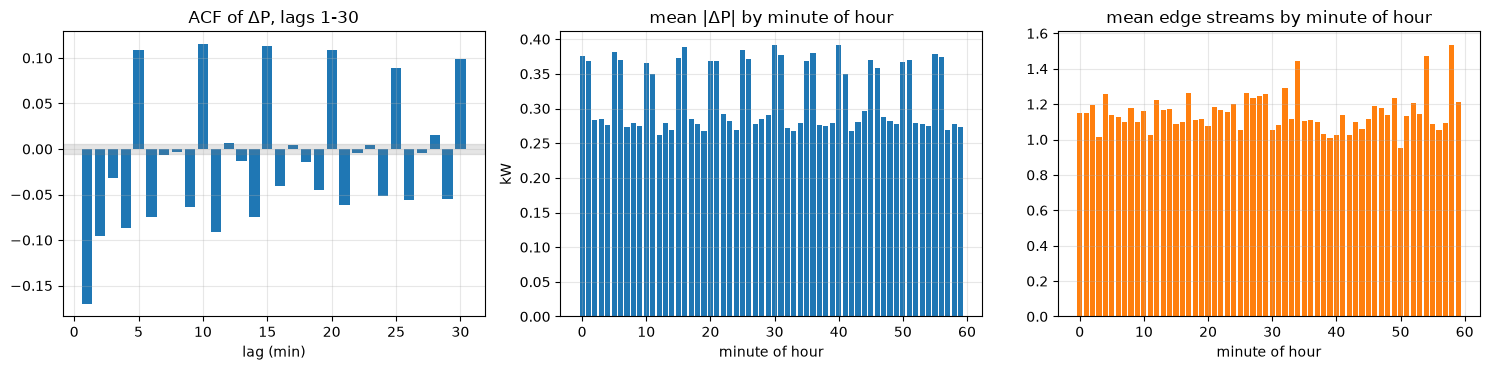

saved: ../reports/figures/eda_julsep/03b_dP_5min_check.png


In [8]:
# Cell 6: Investigate the 5-minute periodicity in dP: ACF(dP) lags 1-30, and dependence of |dP|,
# dP sign and edge-stream counts on the minute of the hour (mod 5 and full 0-59).
acf_dp30 = acf_valid(dp, ok_dp, np.arange(1, 31)) if (mu_y := np.nanmean(dp[ok_dp])) is not None else None
mu_y = mu
print("ACF(dP) lags 1-30:")
for r in range(0, 30, 10):
    print("  " + " | ".join(f"{k + 1:>2}: {acf_dp30[k]:+.3f}" for k in range(r, r + 10)))

d = df.with_columns(pl.Series("dP_kW", dp), pl.Series("ok_dp", ok_dp),
                    pl.col("minute_local").dt.minute().alias("mm")).filter(pl.col("ok_dp"))
by5 = (d.group_by((pl.col("mm") % 5).alias("mm_mod5"))
         .agg(pl.len().alias("n"), pl.col("dP_kW").mean().round(4).alias("mean_dP"),
              pl.col("dP_kW").abs().mean().round(4).alias("mean_abs_dP"),
              pl.col("n_edge_streams").mean().round(2).alias("mean_edge"),
              pl.col("n_gpu_streams").mean().round(2).alias("mean_streams"))
         .sort("mm_mod5"))
print("\nby minute of hour mod 5:")
print(by5)

by60 = d.group_by("mm").agg(pl.col("dP_kW").abs().mean().alias("mean_abs_dP"),
                            pl.col("dP_kW").mean().alias("mean_dP"),
                            pl.col("n_edge_streams").mean().alias("mean_edge")).sort("mm")
top = by60.sort("mean_abs_dP", descending=True).head(8)
print("\nminutes of the hour with the largest mean |dP|:")
print(top)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].bar(np.arange(1, 31), acf_dp30, width=0.8); axes[0].axhspan(-band, band, color="grey", alpha=0.2)
axes[0].set(title="ACF of ΔP, lags 1-30", xlabel="lag (min)")
axes[1].bar(by60["mm"], by60["mean_abs_dP"], width=0.8)
axes[1].set(title="mean |ΔP| by minute of hour", xlabel="minute of hour", ylabel="kW")
axes[2].bar(by60["mm"], by60["mean_edge"], width=0.8, color="tab:orange")
axes[2].set(title="mean edge streams by minute of hour", xlabel="minute of hour")
for a in axes: a.grid(alpha=0.3)
fig.tight_layout()
p = FIG / "03b_dP_5min_check.png"
fig.savefig(p, dpi=150)
plt.show()
print("saved:", p)

In [9]:
# Cell 7: Coverage artifact or real power dip? Compare, by minute of hour mod 5, the time-weighted GPU
# count (n_gpu_equiv), its change, power per GPU-equivalent and its change, and stream counts.
d2 = (df.with_columns(pl.col("minute_local").dt.minute().alias("mm"),
                      (pl.col("power_W") / pl.col("n_gpu_equiv")).alias("W_per_gpu"))
        .with_columns(pl.col("n_gpu_equiv").diff().alias("d_ngpu"),
                      pl.col("W_per_gpu").diff().alias("d_Wpg"),
                      pl.col("n_gpu_streams").diff().alias("d_streams"))
        .with_columns(pl.Series("ok_dp", ok_dp))
        .filter(pl.col("ok_dp") & (pl.col("n_gpu_equiv") > 0)))

chk = (d2.group_by((pl.col("mm") % 5).alias("mm_mod5"))
         .agg(pl.len().alias("n"),
              pl.col("n_gpu_equiv").mean().round(3).alias("mean_ngpu_eq"),
              pl.col("d_ngpu").mean().round(4).alias("mean_d_ngpu_eq"),
              pl.col("n_gpu_streams").mean().round(2).alias("mean_streams"),
              pl.col("d_streams").mean().round(4).alias("mean_d_streams"),
              pl.col("W_per_gpu").mean().round(3).alias("mean_W_per_gpu"),
              pl.col("d_Wpg").mean().round(4).alias("mean_d_W_per_gpu"))
         .sort("mm_mod5"))
print("by minute of hour mod 5 (valid consecutive minutes, n_gpu_equiv > 0):")
print(chk)

# ratio n_gpu_equiv / n_gpu_streams: < 1 means streams cover only part of the minute
d2 = d2.with_columns((pl.col("n_gpu_equiv") / pl.col("n_gpu_streams")).alias("cover"))
cov = d2.group_by((pl.col("mm") % 5).alias("mm_mod5")).agg(
    pl.col("cover").mean().round(5).alias("mean_cover"),
    pl.col("cover").quantile(0.05).round(5).alias("p05_cover")).sort("mm_mod5")
print("\ncoverage ratio n_gpu_equiv / n_gpu_streams by minute mod 5:")
print(cov)

for col, lab in [("mean_d_ngpu_eq", "n_gpu_equiv"), ("mean_d_W_per_gpu", "W per GPU-equivalent")]:
    v0 = chk.filter(pl.col("mm_mod5") == 0)[col][0]; v1 = chk.filter(pl.col("mm_mod5") == 1)[col][0]
    print(f"{lab}: mean change at mod5 = 0: {v0:+.4f} | at mod5 = 1: {v1:+.4f}")

by minute of hour mod 5 (valid consecutive minutes, n_gpu_equiv > 0):
shape: (5, 8)
┌─────────┬───────┬─────────────┬─────────────┬─────────────┬────────────┬────────────┬────────────┐
│ mm_mod5 ┆ n     ┆ mean_ngpu_e ┆ mean_d_ngpu ┆ mean_stream ┆ mean_d_str ┆ mean_W_per ┆ mean_d_W_p │
│ ---     ┆ ---   ┆ q           ┆ _eq         ┆ s           ┆ eams       ┆ _gpu       ┆ er_gpu     │
│ i8      ┆ u32   ┆ ---         ┆ ---         ┆ ---         ┆ ---        ┆ ---        ┆ ---        │
│         ┆       ┆ f64         ┆ f64         ┆ f64         ┆ f64        ┆ f64        ┆ f64        │
╞═════════╪═══════╪═════════════╪═════════════╪═════════════╪════════════╪════════════╪════════════╡
│ 0       ┆ 25608 ┆ 333.133     ┆ 0.0294      ┆ 333.68      ┆ -0.0344    ┆ 89.843     ┆ -0.6073    │
│ 1       ┆ 25612 ┆ 333.143     ┆ -0.0016     ┆ 333.71      ┆ 0.0266     ┆ 90.448     ┆ 0.6039     │
│ 2       ┆ 25612 ┆ 333.165     ┆ 0.0107      ┆ 333.75      ┆ 0.0223     ┆ 90.434     ┆ -0.012     │
│ 3    

In [10]:
# Cell 8: Stream-level test of the 5-minute dip on the dev-week stream Parquets
# (2021-09-10..09-17 file clock; interior stream-minutes only; maintenance day 2021-09-16 excluded).
# Question: does the dip appear inside each GPU stream (same GPU, consecutive minutes), and do minutes
# at mod 5 = 0 have fewer samples (logging gap) than other minutes?
import polars as pl
SD = "../data/interim/streams_dev"
s = (pl.scan_parquet(f"{SD}/*.parquet")
       .select("file", "gpu_index", "minute_epoch", "power_W", "n_samples")
       .collect())
print(f"stream-minute rows (all): {s.height:,}  (expected 3,210,563)")
key = ["file", "gpu_index"]
s = (s.with_columns(pl.col("minute_epoch").min().over(key).alias("m0"),
                    pl.col("minute_epoch").max().over(key).alias("m1"))
      .filter((pl.col("minute_epoch") > pl.col("m0")) & (pl.col("minute_epoch") < pl.col("m1")))
      .with_columns(pl.from_epoch("minute_epoch", time_unit="s").alias("t"))
      .filter(pl.col("t").dt.date() != pl.date(2021, 9, 16))
      .sort(key + ["minute_epoch"])
      .with_columns(pl.col("n_samples").median().over(key).alias("ns_med"),
                    pl.col("power_W").diff().over(key).alias("dP_raw"),
                    pl.col("minute_epoch").diff().over(key).alias("dt"),
                    ((pl.col("minute_epoch") // 60) % 5).alias("mm_mod5"))
      .with_columns((pl.col("n_samples") / pl.col("ns_med")).alias("rel_ns"),
                    pl.when(pl.col("dt") == 60).then(pl.col("dP_raw")).otherwise(None).alias("dP_s")))
print(f"interior stream-minutes kept (16 Sep excluded): {s.height:,} | streams: {s.select(key).unique().height:,} | "
      f"within-stream consecutive steps: {s['dP_s'].is_not_null().sum():,}")

tab = (s.group_by("mm_mod5").agg(
          pl.len().alias("n"),
          pl.col("n_samples").mean().round(2).alias("mean_ns"),
          pl.col("rel_ns").mean().round(5).alias("mean_rel_ns"),
          (pl.col("rel_ns") < 0.98).mean().round(5).alias("share_rel_lt_098"),
          pl.col("power_W").mean().round(3).alias("mean_P_W"),
          pl.col("dP_s").mean().round(4).alias("mean_dP_W"),
          pl.col("dP_s").median().round(4).alias("med_dP_W"),
          (pl.col("dP_s") < 0).mean().round(4).alias("share_dP_neg"))
       .sort("mm_mod5"))
print("\nA. per stream-minute, by minute of hour mod 5 (n_samples, power level, within-stream dP in W):")
print(tab)

full = (s.filter(pl.col("rel_ns") >= 0.98).group_by("mm_mod5")
          .agg(pl.col("dP_s").is_not_null().sum().alias("n_steps"),
               pl.col("dP_s").mean().round(4).alias("mean_dP_W_full_samples"))
          .sort("mm_mod5"))
print("\nB. within-stream dP only where the minute has full samples (rel_ns >= 0.98):")
print(full)

q = (s.filter(pl.col("mm_mod5").is_in([0, 1, 2])).group_by("mm_mod5")
       .agg([pl.col("dP_s").quantile(p).round(3).alias(f"p{int(round(p * 100)):02d}")
             for p in (0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99)])
       .sort("mm_mod5"))
print("\nC. quantiles of within-stream dP (W) at mod 5 = 0, 1, 2:")
print(q)

imp = (s.group_by("mm_mod5")
         .agg((pl.col("dP_s").sum() / pl.col("minute_epoch").n_unique() / 1000).round(4).alias("implied_kW_per_minute"))
         .sort("mm_mod5"))
sd = (pl.read_parquet("../data/processed/series_dev.parquet").sort("minute_epoch")
        .with_columns(pl.from_epoch("minute_epoch", time_unit="s").alias("t"),
                      pl.col("power_W").diff().alias("dP"),
                      pl.col("minute_epoch").diff().alias("dt"),
                      ((pl.col("minute_epoch") // 60) % 5).alias("mm_mod5"))
        .filter((pl.col("t").dt.date() != pl.date(2021, 9, 16)) & (pl.col("dt") == 60) & pl.col("dP").is_not_null()))
ser = (sd.group_by("mm_mod5").agg(pl.len().alias("n_min"), (pl.col("dP").mean() / 1000).round(4).alias("series_mean_dP_kW"))
         .sort("mm_mod5"))
print("\nD. dev-week series mean dP (kW) vs dP implied by within-stream steps (kW per minute):")
print(ser.join(imp, on="mm_mod5"))

stream-minute rows (all): 3,210,563  (expected 3,210,563)
interior stream-minutes kept (16 Sep excluded): 3,082,471 | streams: 6,024 | within-stream consecutive steps: 3,076,447

A. per stream-minute, by minute of hour mod 5 (n_samples, power level, within-stream dP in W):
shape: (5, 9)
┌─────────┬────────┬─────────┬─────────────┬───┬──────────┬───────────┬──────────┬──────────────┐
│ mm_mod5 ┆ n      ┆ mean_ns ┆ mean_rel_ns ┆ … ┆ mean_P_W ┆ mean_dP_W ┆ med_dP_W ┆ share_dP_neg │
│ ---     ┆ ---    ┆ ---     ┆ ---         ┆   ┆ ---      ┆ ---       ┆ ---      ┆ ---          │
│ i64     ┆ u32    ┆ f64     ┆ f64         ┆   ┆ f64      ┆ f64       ┆ f64      ┆ f64          │
╞═════════╪════════╪═════════╪═════════════╪═══╪══════════╪═══════════╪══════════╪══════════════╡
│ 0       ┆ 616208 ┆ 567.48  ┆ 0.99966     ┆ … ┆ 86.998   ┆ -0.2988   ┆ -0.0056  ┆ 0.5273       │
│ 1       ┆ 616520 ┆ 567.46  ┆ 0.99963     ┆ … ┆ 87.293   ┆ 0.3076    ┆ 0.0049   ┆ 0.4768       │
│ 2       ┆ 616680 ┆ 567.4

In [11]:
# Cell 9: Is the 5-minute dip stable over time? Mean dP at mod 5 = 0 and 1 by month and by ISO week,
# total (kW) and per GPU-equivalent (W). Simplified validity: no outage, no maintenance day,
# power > 0, consecutive minutes only (may differ slightly from cell 6).
import polars as pl
f = (pl.read_parquet("../data/processed/series_julsep_features.parquet").sort("minute_epoch")
       .with_columns((pl.col("power_W") / pl.col("n_gpu_equiv")).alias("Wpg"))
       .with_columns(pl.col("power_W").diff().alias("dP"),
                     pl.col("Wpg").diff().alias("dWpg"),
                     pl.col("minute_epoch").diff().alias("dt"),
                     (pl.col("outage") | pl.col("maint_day") | (pl.col("power_W") <= 0)).alias("bad"))
       .with_columns(pl.col("bad").shift(1).alias("bad_prev"))
       .filter((pl.col("dt") == 60) & ~pl.col("bad") & ~pl.col("bad_prev").fill_null(True)
               & pl.col("dP").is_not_null())
       .with_columns(((pl.col("minute_epoch") // 60) % 5).alias("mm_mod5"),
                     pl.col("minute_local").dt.strftime("%Y-%m").alias("month"),
                     pl.col("minute_local").dt.week().alias("iso_week")))
print(f"valid consecutive minutes: {f.height:,}")

def table(by):
    g = (f.filter(pl.col("mm_mod5").is_in([0, 1, 2, 3, 4]))
           .group_by([by, "mm_mod5"])
           .agg((pl.col("dP").mean() / 1000).alias("dP_kW"), pl.col("dWpg").mean().alias("dWpg_W"),
                pl.len().alias("n")))
    out = (g.with_columns(pl.when(pl.col("mm_mod5") == 0).then(pl.lit("m0"))
                            .when(pl.col("mm_mod5") == 1).then(pl.lit("m1"))
                            .otherwise(pl.lit("m234")).alias("grp"))
             .group_by([by, "grp"])
             .agg((pl.col("dP_kW") * pl.col("n")).sum() / pl.col("n").sum(),
                  (pl.col("dWpg_W") * pl.col("n")).sum() / pl.col("n").sum(),
                  pl.col("n").sum())
             .pivot(on="grp", index=by, values=["dP_kW", "dWpg_W", "n"])
             .sort(by))
    return out.with_columns([pl.col(c).round(4) for c in out.columns if c.startswith("dP_kW") or c.startswith("dWpg_W")])

pl.Config.set_tbl_cols(20); pl.Config.set_tbl_width_chars(200)
print("\nby month (dP_kW = mean change of total power; dWpg_W = mean change of W per GPU-equivalent):")
print(table("month"))
print("\nby ISO week:")
p

valid consecutive minutes: 128,054

by month (dP_kW = mean change of total power; dWpg_W = mean change of W per GPU-equivalent):
shape: (3, 10)
┌─────────┬──────────┬────────────┬──────────┬───────────┬─────────────┬───────────┬──────┬────────┬──────┐
│ month   ┆ dP_kW_m0 ┆ dP_kW_m234 ┆ dP_kW_m1 ┆ dWpg_W_m0 ┆ dWpg_W_m234 ┆ dWpg_W_m1 ┆ n_m0 ┆ n_m234 ┆ n_m1 │
│ ---     ┆ ---      ┆ ---        ┆ ---      ┆ ---       ┆ ---         ┆ ---       ┆ ---  ┆ ---    ┆ ---  │
│ str     ┆ f64      ┆ f64        ┆ f64      ┆ f64       ┆ f64         ┆ f64       ┆ u32  ┆ u32    ┆ u32  │
╞═════════╪══════════╪════════════╪══════════╪═══════════╪═════════════╪═══════════╪══════╪════════╪══════╡
│ 2021-07 ┆ -0.3596  ┆ 0.0007     ┆ 0.3557   ┆ -1.0647   ┆ 0.0034      ┆ 1.0513    ┆ 8638 ┆ 25920  ┆ 8640 │
│ 2021-08 ┆ -0.1635  ┆ 0.0012     ┆ 0.1648   ┆ -0.4434   ┆ 0.007       ┆ 0.4556    ┆ 8619 ┆ 25858  ┆ 8620 │
│ 2021-09 ┆ -0.0963  ┆ 0.001      ┆ 0.0914   ┆ -0.3035   ┆ 0.0022      ┆ 0.2942    ┆ 8351 ┆ 25056  ┆

PosixPath('../reports/figures/eda_julsep/03b_dP_5min_check.png')

In [12]:
print(table("iso_week"))

shape: (14, 10)
┌──────────┬────────────┬──────────┬──────────┬─────────────┬───────────┬───────────┬────────┬──────┬──────┐
│ iso_week ┆ dP_kW_m234 ┆ dP_kW_m1 ┆ dP_kW_m0 ┆ dWpg_W_m234 ┆ dWpg_W_m1 ┆ dWpg_W_m0 ┆ n_m234 ┆ n_m1 ┆ n_m0 │
│ ---      ┆ ---        ┆ ---      ┆ ---      ┆ ---         ┆ ---       ┆ ---       ┆ ---    ┆ ---  ┆ ---  │
│ i8       ┆ f64        ┆ f64      ┆ f64      ┆ f64         ┆ f64       ┆ f64       ┆ u32    ┆ u32  ┆ u32  │
╞══════════╪════════════╪══════════╪══════════╪═════════════╪═══════════╪═══════════╪════════╪══════╪══════╡
│ 26       ┆ 0.0047     ┆ 0.2466   ┆ -0.2554  ┆ 0.0139      ┆ 0.7454    ┆ -0.7685   ┆ 3456   ┆ 1152 ┆ 1151 │
│ 27       ┆ 0.0014     ┆ 0.3639   ┆ -0.3725  ┆ 0.0066      ┆ 1.0796    ┆ -1.104    ┆ 6048   ┆ 2016 ┆ 2016 │
│ 28       ┆ 0.0013     ┆ 0.1431   ┆ -0.1534  ┆ 0.0052      ┆ 0.4136    ┆ -0.447    ┆ 5184   ┆ 1728 ┆ 1727 │
│ 29       ┆ 0.0068     ┆ 0.5341   ┆ -0.5612  ┆ 0.0229      ┆ 1.6308    ┆ -1.7102   ┆ 6048   ┆ 2016 ┆ 2016 │
│ 3

In [13]:
pl.Config.set_tbl_rows(30)
print(table("iso_week"))

shape: (14, 10)
┌──────────┬────────────┬──────────┬──────────┬─────────────┬───────────┬───────────┬────────┬──────┬──────┐
│ iso_week ┆ dP_kW_m234 ┆ dP_kW_m1 ┆ dP_kW_m0 ┆ dWpg_W_m234 ┆ dWpg_W_m1 ┆ dWpg_W_m0 ┆ n_m234 ┆ n_m1 ┆ n_m0 │
│ ---      ┆ ---        ┆ ---      ┆ ---      ┆ ---         ┆ ---       ┆ ---       ┆ ---    ┆ ---  ┆ ---  │
│ i8       ┆ f64        ┆ f64      ┆ f64      ┆ f64         ┆ f64       ┆ f64       ┆ u32    ┆ u32  ┆ u32  │
╞══════════╪════════════╪══════════╪══════════╪═════════════╪═══════════╪═══════════╪════════╪══════╪══════╡
│ 26       ┆ 0.0047     ┆ 0.2466   ┆ -0.2554  ┆ 0.0139      ┆ 0.7454    ┆ -0.7685   ┆ 3456   ┆ 1152 ┆ 1151 │
│ 27       ┆ 0.0014     ┆ 0.3639   ┆ -0.3725  ┆ 0.0066      ┆ 1.0796    ┆ -1.104    ┆ 6048   ┆ 2016 ┆ 2016 │
│ 28       ┆ 0.0013     ┆ 0.1431   ┆ -0.1534  ┆ 0.0052      ┆ 0.4136    ┆ -0.447    ┆ 5184   ┆ 1728 ┆ 1727 │
│ 29       ┆ 0.0068     ┆ 0.5341   ┆ -0.5612  ┆ 0.0229      ┆ 1.6308    ┆ -1.7102   ┆ 6048   ┆ 2016 ┆ 2016 │
│ 3

In [14]:
# Cell 10: Daily view of the 5-minute dip around the maintenance days 2021-07-15, 2021-08-10, 2021-09-16.
pl.Config.set_tbl_rows(80)
dd = (f.with_columns(pl.col("minute_local").dt.date().alias("date"),
                     pl.when(pl.col("mm_mod5") == 0).then(pl.lit("m0"))
                       .when(pl.col("mm_mod5") == 1).then(pl.lit("m1"))
                       .otherwise(pl.lit("m234")).alias("grp"))
       .group_by(["date", "grp"])
       .agg(pl.col("dWpg").mean().round(3).alias("dWpg_W"), pl.len().alias("n"))
       .pivot(on="grp", index="date", values=["dWpg_W", "n"])
       .sort("date")
       .select("date", "dWpg_W_m0", "dWpg_W_m1", "dWpg_W_m234", "n_m0"))
for a, b in [("2021-07-08", "2021-07-22"), ("2021-08-03", "2021-08-20"), ("2021-09-09", "2021-09-23")]:
    print(f"\n{a} .. {b} (W per GPU-equivalent; maintenance days are excluded, so they are missing):")
    print(dd.filter((pl.col("date") >= pl.lit(a).str.to_date()) & (pl.col("date") <= pl.lit(b).str.to_date())))


2021-07-08 .. 2021-07-22 (W per GPU-equivalent; maintenance days are excluded, so they are missing):
shape: (14, 5)
┌────────────┬───────────┬───────────┬─────────────┬──────┐
│ date       ┆ dWpg_W_m0 ┆ dWpg_W_m1 ┆ dWpg_W_m234 ┆ n_m0 │
│ ---        ┆ ---       ┆ ---       ┆ ---         ┆ ---  │
│ date       ┆ f64       ┆ f64       ┆ f64         ┆ u32  │
╞════════════╪═══════════╪═══════════╪═════════════╪══════╡
│ 2021-07-08 ┆ -1.212    ┆ 0.952     ┆ 0.086       ┆ 288  │
│ 2021-07-09 ┆ -0.849    ┆ 0.887     ┆ -0.014      ┆ 288  │
│ 2021-07-10 ┆ -1.327    ┆ 1.301     ┆ 0.011       ┆ 288  │
│ 2021-07-11 ┆ -1.732    ┆ 1.846     ┆ -0.04       ┆ 288  │
│ 2021-07-12 ┆ -0.605    ┆ 0.616     ┆ -0.002      ┆ 288  │
│ 2021-07-13 ┆ -1.01     ┆ 0.941     ┆ 0.015       ┆ 288  │
│ 2021-07-14 ┆ -0.521    ┆ 0.501     ┆ -0.064      ┆ 288  │
│ 2021-07-16 ┆ -0.55     ┆ 0.309     ┆ 0.11        ┆ 287  │
│ 2021-07-17 ┆ -0.056    ┆ 0.104     ┆ -0.037      ┆ 288  │
│ 2021-07-18 ┆ 0.059     ┆ 0.011     ┆ 0.00

In [15]:
# Cell 11: Is the 5-minute dip concentrated in a few jobs (files)? Uses `s` from cell 8 (dev-week streams,
# interior minutes, 16 Sep excluded). Placebo: the same ranking on mod 5 = 2, where there is no dip (noise floor).
pf = (s.filter(pl.col("dP_s").is_not_null())
       .group_by("file")
       .agg(pl.col("gpu_index").n_unique().alias("n_gpu"),
            pl.len().alias("n_steps"),
            pl.col("power_W").mean().round(1).alias("mean_P_W"),
            pl.col("dP_s").filter(pl.col("mm_mod5") == 0).sum().alias("sum_m0"),
            pl.col("dP_s").filter(pl.col("mm_mod5") == 2).sum().alias("sum_m2"),
            pl.col("dP_s").filter(pl.col("mm_mod5") == 0).mean().alias("mean_m0"),
            pl.col("dP_s").filter(pl.col("mm_mod5").is_in([2, 3, 4])).mean().alias("mean_m234")))
tot0, tot2 = pf["sum_m0"].sum(), pf["sum_m2"].sum()
print(f"files: {pf.height:,} | total sum of dP at mod0: {tot0:,.0f} W | at mod2 (placebo): {tot2:,.0f} W")

by0 = pf.sort("sum_m0")
by2 = pf.sort("sum_m2")
print("\nmost negative files: sum of dP at mod0 vs the same count ranked on mod2 (noise floor):")
for k in (10, 50, 100, 500, 1000):
    print(f"top {k:>4}: mod0 sum {by0['sum_m0'][:k].sum():>12,.0f} W (share of total mod0 {by0['sum_m0'][:k].sum() / tot0:6.3f}) | "
          f"noise floor mod2 {by2['sum_m2'][:k].sum():>12,.0f} W")

ex = pf.filter(pl.col("mean_m0").is_not_null() & pl.col("mean_m234").is_not_null())
ex = ex.with_columns((pl.col("mean_m0") - pl.col("mean_m234")).alias("excess"))
print(f"\nshare of files with mean dP at mod0 below mean at mod2-4: {(ex['excess'] < 0).mean():.3f} (n = {ex.height:,})")
print(f"same, files with at least 1,000 steps: {(ex.filter(pl.col('n_steps') >= 1000)['excess'] < 0).mean():.3f} "
      f"(n = {ex.filter(pl.col('n_steps') >= 1000).height:,})")

print("\n15 files with the most negative mod0 sum:")
print(by0.head(15).with_columns(pl.col("sum_m0").round(0), pl.col("sum_m2").round(0),
                                pl.col("mean_m0").round(3), pl.col("mean_m234").round(3)))

files: 5,037 | total sum of dP at mod0: -183,773 W | at mod2 (placebo): 14,881 W

most negative files: sum of dP at mod0 vs the same count ranked on mod2 (noise floor):
top   10: mod0 sum      -41,724 W (share of total mod0  0.227) | noise floor mod2       -8,622 W
top   50: mod0 sum     -119,327 W (share of total mod0  0.649) | noise floor mod2      -24,295 W
top  100: mod0 sum     -154,421 W (share of total mod0  0.840) | noise floor mod2      -34,603 W
top  500: mod0 sum     -216,512 W (share of total mod0  1.178) | noise floor mod2      -57,068 W
top 1000: mod0 sum     -233,930 W (share of total mod0  1.273) | noise floor mod2      -60,963 W

share of files with mean dP at mod0 below mean at mod2-4: 0.576 (n = 5,013)
same, files with at least 1,000 steps: 0.663 (n = 602)

15 files with the most negative mod0 sum:
shape: (15, 8)
┌─────────────────────────────────┬───────┬─────────┬──────────┬─────────┬────────┬─────────┬───────────┐
│ file                            ┆ n_gpu ┆ n_step

rows 132,480 | train ends before index 92,736 (2021-09-03 09:36:00) | val ends before 112,608 (2021-09-17 04:48:00)
post-maintenance zero minutes: 92 | valid minutes: 128,068 | train median power 31.52 kW

ramp statistics on train pairs (kW):
shape: (3, 17)
┌─────┬─────────┬───────┬─────────┬───────┬───────┬───────┬────────┬─────────┬───────────────────┬───────────────────┬───────────┬───────┬────────────┬────────┬────────────┬─────────────┐
│ h   ┆ n_train ┆ std   ┆ med_abs ┆ p90   ┆ p95   ┆ p99   ┆ max    ┆ ex_kurt ┆ share_up_of_ramps ┆ p95_pct_of_median ┆ ramps_val ┆ n_val ┆ ramps_test ┆ n_test ┆ severe_val ┆ severe_test │
│ --- ┆ ---     ┆ ---   ┆ ---     ┆ ---   ┆ ---   ┆ ---   ┆ ---    ┆ ---     ┆ ---               ┆ ---               ┆ ---       ┆ ---   ┆ ---        ┆ ---    ┆ ---        ┆ ---         │
│ i64 ┆ i64     ┆ f64   ┆ f64     ┆ f64   ┆ f64   ┆ f64   ┆ f64    ┆ f64     ┆ f64               ┆ f64               ┆ i64       ┆ i64   ┆ i64        ┆ i64    ┆ i64        ┆ i64 

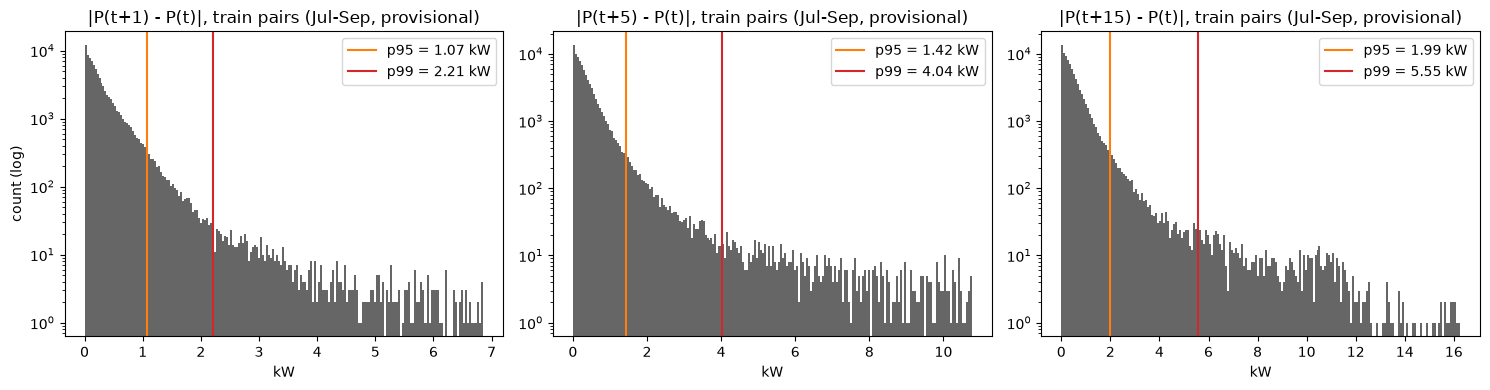

../reports/figures/eda_julsep/04_ramp_thresholds.png


In [16]:
# Cell 12 (H2): Ramp thresholds per horizon on |P(t+h) - P(t)| (kW), both ends valid; train = both ends in the
# first 70% (by minute index). valid = not outage, not maintenance day, not post-maintenance zero minute.
# Also: effect of the 5-minute dip on the h = 1 threshold (pairs touching a minute with mod 5 = 0 removed).
import numpy as np, polars as pl, matplotlib.pyplot as plt
from datetime import timedelta
from pathlib import Path
FIG = Path("../reports/figures/eda_julsep")
g = (pl.read_parquet("../data/processed/series_julsep_features.parquet").sort("minute_epoch")
       .with_columns(pl.col("minute_local").dt.date().alias("date")))
maint = g.filter(pl.col("maint_day"))["date"].unique().to_list()
post = [d + timedelta(days=1) for d in maint]
g = g.with_columns(((pl.col("power_W") == 0) & pl.col("date").is_in(post)).fill_null(False).alias("pmz"))
n = g.height; i_tr = int(0.7 * n); i_va = int(0.85 * n)
P = g["power_W"].cast(pl.Float64).fill_null(np.nan).to_numpy() / 1000
valid = (~g["outage"] & ~g["maint_day"] & ~g["pmz"]).to_numpy() & ~np.isnan(P)
mm = (g["minute_epoch"].to_numpy() // 60) % 5
med_tr = np.nanmedian(P[:i_tr][valid[:i_tr]])
print(f"rows {n:,} | train ends before index {i_tr:,} ({g['minute_local'][i_tr]}) | val ends before {i_va:,} ({g['minute_local'][i_va]})")
print(f"post-maintenance zero minutes: {int(g['pmz'].sum())} | valid minutes: {int(valid.sum()):,} | train median power {med_tr:.2f} kW")

def pairs(h):
    t = np.arange(n - h)
    ok = valid[t] & valid[t + h]
    d = P[t + h] - P[t]
    tr = ok & (t + h < i_tr)
    va = ok & (t >= i_tr) & (t + h < i_va)
    te = ok & (t >= i_va)
    return t, d, tr, va, te

rows, hist = [], {}
for h in (1, 5, 15):
    t, d, tr, va, te = pairs(h)
    a = np.abs(d[tr]); x = d[tr] - d[tr].mean()
    p90, p95, p99 = np.quantile(a, [0.90, 0.95, 0.99])
    rows.append(dict(h=h, n_train=int(tr.sum()), std=x.std(), med_abs=np.median(a), p90=p90, p95=p95, p99=p99,
                     max=a.max(), ex_kurt=(x**4).mean() / (x**2).mean()**2 - 3,
                     share_up_of_ramps=(d[tr][a > p95] > 0).mean(),
                     p95_pct_of_median=100 * p95 / med_tr,
                     ramps_val=int((np.abs(d[va]) > p95).sum()), n_val=int(va.sum()),
                     ramps_test=int((np.abs(d[te]) > p95).sum()), n_test=int(te.sum()),
                     severe_val=int((np.abs(d[va]) > p99).sum()), severe_test=int((np.abs(d[te]) > p99).sum())))
    hist[h] = (a, p95, p99)
res = pl.DataFrame(rows).with_columns([pl.col(c).round(3) for c in ["std", "med_abs", "p90", "p95", "p99", "max",
                                                                     "ex_kurt", "share_up_of_ramps", "p95_pct_of_median"]])
pl.Config.set_tbl_cols(20); pl.Config.set_tbl_width_chars(250)
print("\nramp statistics on train pairs (kW):")
print(res)
print("dev week (for comparison): p95 0.618 / 1.005 / 1.684 ; p99 1.133 / 2.183 / 3.281 kW")

t, d, tr, _, _ = pairs(1)
keep = tr & (mm[t] != 0) & (mm[t + 1] != 0)
a_all, a_no0 = np.abs(d[tr]), np.abs(d[keep])
print(f"\nh = 1, train: all pairs n = {tr.sum():,}: p95 {np.quantile(a_all, 0.95):.3f}, p99 {np.quantile(a_all, 0.99):.3f} | "
      f"pairs not touching mod5 = 0 n = {keep.sum():,}: p95 {np.quantile(a_no0, 0.95):.3f}, p99 {np.quantile(a_no0, 0.99):.3f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, h in zip(axes, (1, 5, 15)):
    a, p95, p99 = hist[h]
    ax.hist(a, bins=200, range=(0, np.quantile(a, 0.999)), color="0.4")
    ax.set_yscale("log")
    ax.axvline(p95, color="tab:orange", label=f"p95 = {p95:.2f} kW")
    ax.axvline(p99, color="tab:red", label=f"p99 = {p99:.2f} kW")
    ax.set_title(f"|P(t+{h}) - P(t)|, train pairs (Jul-Sep, provisional)")
    ax.set_xlabel("kW"); ax.legend()
axes[0].set_ylabel("count (log)")
plt.tight_layout()
out = FIG / "04_ramp_thresholds.png"
plt.savefig(out, dpi=150); plt.show()
print(out)

In [17]:
# Cell 13: The largest one-minute changes in train (h = 1): when, and do GPU count or per-GPU power change?
t, d, tr, _, _ = pairs(1)
idx = np.where(tr)[0]
a = np.abs(d[idx])
print(f"train pairs h = 1: {idx.size:,} | |dP| > 3 kW: {(a > 3).sum()} | > 5 kW: {(a > 5).sum()} | > 10 kW: {(a > 10).sum()}")
top = np.sort(idx[np.argsort(-a)[:15]])
ng = g["n_gpu_equiv"].to_numpy(); ga = g["gpus_alloc"].to_numpy(); ml = g["minute_local"].to_list()
mdates = set(maint)
print("\n15 largest |dP| (sorted by time); 'days after maint' = days since the last maintenance day:")
for k in top:
    last = max([m for m in mdates if m <= ml[k].date()], default=None)
    dd_ = (ml[k].date() - last).days if last else None
    print(f"{ml[k]} | P {P[k]:6.2f} -> {P[k+1]:6.2f} kW (d {d[k]:+6.2f}) | n_gpu_equiv {ng[k]:6.1f} -> {ng[k+1]:6.1f} | "
          f"gpus_alloc {ga[k]} -> {ga[k+1]} | W/GPU {1000*P[k]/ng[k]:6.1f} -> {1000*P[k+1]/ng[k+1]:6.1f} | days after maint {dd_}")

train pairs h = 1: 89,751 | |dP| > 3 kW: 530 | > 5 kW: 212 | > 10 kW: 22

15 largest |dP| (sorted by time); 'days after maint' = days since the last maintenance day:
2021-07-14 23:57:00 | P  20.81 ->   3.53 kW (d -17.27) | n_gpu_equiv  232.8 ->   47.8 | gpus_alloc 181 -> 0 | W/GPU   89.4 ->   73.9 | days after maint None
2021-07-16 19:14:00 | P  25.10 ->  35.97 kW (d +10.86) | n_gpu_equiv  362.9 ->  360.0 | gpus_alloc 363 -> 359 | W/GPU   69.2 ->   99.9 | days after maint 1
2021-07-16 19:26:00 | P  23.55 ->  35.69 kW (d +12.13) | n_gpu_equiv  350.0 ->  346.9 | gpus_alloc 349 -> 347 | W/GPU   67.3 ->  102.9 | days after maint 1
2021-07-16 19:42:00 | P  24.01 ->  35.75 kW (d +11.74) | n_gpu_equiv  360.0 ->  361.1 | gpus_alloc 360 -> 357 | W/GPU   66.7 ->   99.0 | days after maint 1
2021-08-03 06:43:00 | P  25.85 ->  38.49 kW (d +12.65) | n_gpu_equiv  360.9 ->  357.7 | gpus_alloc 360 -> 358 | W/GPU   71.6 ->  107.6 | days after maint 19
2021-08-11 00:28:00 | P  45.94 ->  14.75 kW (d -31.1

In [18]:
# Cell 14: Effect on ramp thresholds of excluding maintenance boundaries (provisional rule for Meeting 1):
# the whole day after a maintenance day and the last hour (23:00-23:59) of the day before it.
pre = [m - timedelta(days=1) for m in maint]
hour = g["minute_local"].dt.hour().to_numpy()
post_day = g["date"].is_in(post).to_numpy()
pre_hour = g["date"].is_in(pre).to_numpy() & (hour == 23)
valid2 = valid & ~post_day & ~pre_hour
print(f"extra minutes removed: day after maintenance {int((valid & post_day).sum()):,} | last hour before {int((valid & pre_hour).sum())}")
for h in (1, 5, 15):
    t = np.arange(n - h); d = P[t + h] - P[t]
    for name, v in (("current rule", valid), ("boundaries excluded", valid2)):
        ok = v[t] & v[t + h]
        tr = ok & (t + h < i_tr); va = ok & (t >= i_tr) & (t + h < i_va); te = ok & (t >= i_va)
        a = np.abs(d[tr]); p95, p99 = np.quantile(a, [0.95, 0.99]); x = d[tr] - d[tr].mean()
        print(f"h={h:>2} {name:<20} n_train {tr.sum():>6,} | p95 {p95:.3f} | p99 {p99:.3f} | max {a.max():6.2f} | "
              f"ex_kurt {(x**4).mean() / (x**2).mean()**2 - 3:6.1f} | ramp share val {(np.abs(d[va]) > p95).mean():.3f} "
              f"test {(np.abs(d[te]) > p95).mean():.3f}")

extra minutes removed: day after maintenance 4,228 | last hour before 180
h= 1 current rule         n_train 89,751 | p95 1.075 | p99 2.209 | max  31.19 | ex_kurt  184.3 | ramp share val 0.020 test 0.022
h= 1 boundaries excluded  n_train 86,853 | p95 1.043 | p99 1.855 | max  12.65 | ex_kurt   30.2 | ramp share val 0.022 test 0.023
h= 5 current rule         n_train 89,699 | p95 1.422 | p99 4.036 | max  33.23 | ex_kurt  100.0 | ramp share val 0.031 test 0.053
h= 5 boundaries excluded  n_train 86,841 | p95 1.322 | p99 3.039 | max  17.82 | ex_kurt   59.3 | ramp share val 0.035 test 0.060
h=15 current rule         n_train 89,627 | p95 1.993 | p99 5.552 | max  40.81 | ex_kurt  108.1 | ramp share val 0.038 test 0.074
h=15 boundaries excluded  n_train 86,811 | p95 1.833 | p99 4.031 | max  17.55 | ex_kurt   37.7 | ramp share val 0.046 test 0.081
